# ECSCI24302 - Machine Learning Essentials
## Project-Based Learning (PBL): End-to-End Machine Learning Pipeline
### Notebook 2: Data Preprocessing & Feature Engineering with Pure Pandas and NumPy

---
**Project Title:** Indian Railways Train Delay Prediction & Network Punctuality Analytics  
**Course Code:** ECSCI24302  
**Core Principles:** **100% Pure Pandas and NumPy Operations for All Data Transformations**  
**Stages Covered in this Notebook:**
* **Stage 6:** Data Preprocessing (Cleaning, Leakage Quarantine & IQR Outlier Clipping with Pandas/NumPy)
* **Stage 7:** Feature Engineering (Vectorized Kinematics & Trigonometric Time Encodings with NumPy)
* **Stage 8:** Feature Selection (Pearson Correlation Matrix with Pandas)
* **Stage 9:** Train-Test Split, One-Hot Encoding (`pd.get_dummies`) & Z-Score Standardization with NumPy
---

In [1]:
# 1. Core Data Manipulation Libraries (Pure Pandas & NumPy)
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('../artifacts', exist_ok=True)
os.makedirs('artifacts', exist_ok=True)

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version:  {np.__version__}")

Pandas version: 3.0.1
NumPy version:  1.26.4


## Stage 6: Data Preprocessing with Pure Pandas and NumPy

### 6.1 Data Cleaning & Leakage Elimination
Using native **Pandas**:
1. **Target Leakage:** `delay_minutes` (direct target determinant) and `primary_delay_cause` (post-arrival outcome) exist only in the training set. They are quarantined and dropped from input features using `df.drop()`.
2. **Identifier Columns:** `journey_id` is an arbitrary string hash, dropped with `df.drop()`.
3. **Zero-Variance Features:** `is_overloaded` is verified constant (`0`) across all rows using `df['is_overloaded'].nunique() == 1`, dropped with `df.drop()`.
4. **Outlier Treatment:** Continuous physical features (`distance_km`, `scheduled_travel_hours`, `psr_count`) are treated using **pure NumPy / Pandas Interquartile Range (IQR) clipping** ($Q_1 - 1.5\times IQR$ to $Q_3 + 1.5\times IQR$) with `np.clip()`.

In [2]:
# Load training corpus using Pandas
DATA_PATH = '../data/' if os.path.exists('../data/') else 'data/'
df_raw = pd.read_csv(os.path.join(DATA_PATH, 'ir_train.csv'), nrows=120000)

print(f"Raw DataFrame loaded with Pandas: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

# 1. Drop Leakage, Identifier, and Zero-Variance Columns using pure Pandas
cols_to_drop = ['delay_minutes', 'primary_delay_cause', 'journey_id', 'is_overloaded', 'departure_date']
df_clean = df_raw.drop(columns=[c for c in cols_to_drop if c in df_raw.columns])

# 2. Outlier Detection and Capping via NumPy / Pandas Interquartile Range (IQR)
outlier_candidates = ['distance_km', 'scheduled_travel_hours', 'psr_count', 'loco_age_years', 'coach_age_years']
iqr_bounds = {}

print("\nApplying NumPy/Pandas IQR Outlier Capping (Winsorization):")
for col in outlier_candidates:
    q25 = df_clean[col].quantile(0.25)
    q75 = df_clean[col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = float(q25 - 1.5 * iqr)
    upper_bound = float(q75 + 1.5 * iqr)
    iqr_bounds[col] = (lower_bound, upper_bound)
    
    # Count outliers before clipping with NumPy
    outlier_count = np.sum((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound))
    # Robustly clip using np.clip
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)
    print(f" -> {col:24s}: IQR={iqr:6.2f} | Bounds=[{lower_bound:6.1f}, {upper_bound:6.1f}] | Capped {outlier_count:,} records")

print(f"\nCleaned DataFrame shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

Raw DataFrame loaded with Pandas: 120,000 rows × 45 columns

Applying NumPy/Pandas IQR Outlier Capping (Winsorization):
 -> distance_km             : IQR=450.00 | Bounds=[-334.0, 1466.0] | Capped 3,779 records
 -> scheduled_travel_hours  : IQR=  7.55 | Bounds=[  -5.3,   24.9] | Capped 1,473 records
 -> psr_count               : IQR=  2.00 | Bounds=[  -1.0,    7.0] | Capped 1,428 records
 -> loco_age_years          : IQR= 13.90 | Bounds=[ -13.2,   42.5] | Capped 0 records
 -> coach_age_years         : IQR= 17.60 | Bounds=[ -12.6,   57.8] | Capped 0 records

Cleaned DataFrame shape: 120,000 rows × 40 columns


## Stage 7: Feature Engineering with Vectorized Pandas and NumPy

All feature modifications are performed using native **Pandas vectorized expressions** and **NumPy trigonometric functions**:

1. **Speed Metric (`avg_speed_kmh`):** Computed as `distance_km / scheduled_travel_hours` via Pandas division.
2. **Stop Density (`stops_density`):** Intermediate halts per 100 km: `num_scheduled_stops / (distance_km / 100 + 0.1)`.
3. **Average Stop Distance (`avg_stop_distance`):** Mean inter-station spacing: `distance_km / (num_scheduled_stops + 1)`.
4. **Composite Weather Severity (`composite_weather_severity`):** Non-linear amplification of monthly severity by monsoon and fog flags.
5. **Network Corridor Vulnerability (`network_vulnerability`):** Congestion index scaled up on HDN corridors and discounted where track is doubled.
6. **Rolling Stock Wear Index (`equipment_age_index`):** Mean of loco age and coach age via `(loco + coach) / 2`.
7. **Rake Turnaround Cascade Risk (`rake_turnaround_risk`):** Multiplicative interaction: `late_incoming_rake * is_rake_shared`.
8. **Historical Route Delay Risk (`historical_delay_risk`):** Complement of on-time percentage: `(100 - ontime_pct) / 100`.
9. **Cyclical Temporal Features via NumPy Trigonometry:**
   - $\text{hour\_sin} = \sin(2\pi \times \text{departure\_hour} / 24)$
   - $\text{hour\_cos} = \cos(2\pi \times \text{departure\_hour} / 24)$
   - $\text{day\_sin} = \sin(2\pi \times \text{day\_of\_week} / 7)$
   - $\text{day\_cos} = \cos(2\pi \times \text{day\_of\_week} / 7)$

In [3]:
def engineer_features_pure_pandas(data: pd.DataFrame) -> pd.DataFrame:
    """
    Vectorized feature engineering executed 100% using Pandas Series & NumPy arrays.
    """
    df = data.copy()
    
    # 1. Kinematic & Geometry Metrics
    df['avg_speed_kmh'] = df['distance_km'] / df['scheduled_travel_hours'].replace(0, np.nan)
    df['stops_density'] = df['num_scheduled_stops'] / (df['distance_km'] / 100.0 + 0.1)
    df['avg_stop_distance'] = df['distance_km'] / (df['num_scheduled_stops'] + 1)
    
    # 2. Weather & Network Vulnerability Interactions
    df['composite_weather_severity'] = df['season_severity_score'] * (
        1.0 + 0.5 * df['is_monsoon_season'] + 0.5 * df['is_fog_risk']
    )
    df['network_vulnerability'] = df['zone_congestion_index'] * (
        1.0 + 0.5 * df['is_hdn_route'] - 0.3 * df['track_doubled']
    )
    
    # 3. Rolling Stock & Turnaround Risk
    df['equipment_age_index'] = (df['loco_age_years'] + df['coach_age_years']) / 2.0
    df['rake_turnaround_risk'] = df['late_incoming_rake'] * df['is_rake_shared']
    df['historical_delay_risk'] = (100.0 - df['route_historical_ontime_pct']) / 100.0
    
    # 4. Cyclical Temporal Encodings using NumPy
    df['hour_sin'] = np.sin(2.0 * np.pi * df['departure_hour'] / 24.0)
    df['hour_cos'] = np.cos(2.0 * np.pi * df['departure_hour'] / 24.0)
    df['day_sin'] = np.sin(2.0 * np.pi * df['day_of_week'] / 7.0)
    df['day_cos'] = np.cos(2.0 * np.pi * df['day_of_week'] / 7.0)
    
    return df

df_engineered = engineer_features_pure_pandas(df_clean)
print(f"Engineered DataFrame Shape: {df_engineered.shape[0]:,} rows × {df_engineered.shape[1]} columns")
print(f"Added 11 domain features purely with Pandas & NumPy.")

Engineered DataFrame Shape: 120,000 rows × 52 columns
Added 11 domain features purely with Pandas & NumPy.


## Stage 8: Feature Selection with Pandas

We evaluate feature correlations directly using `DataFrame.corr(numeric_only=True)` to confirm the predictive utility of the newly engineered variables.

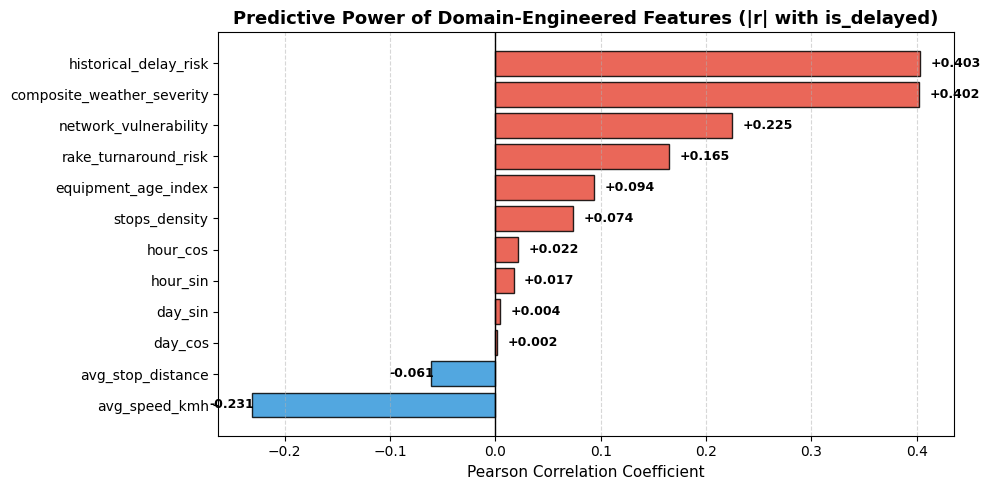

In [4]:
# Calculate Pearson correlations using Pandas
eng_features = [
    'composite_weather_severity', 'historical_delay_risk', 'network_vulnerability',
    'rake_turnaround_risk', 'avg_speed_kmh', 'equipment_age_index', 'stops_density',
    'avg_stop_distance', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos'
]

eng_corrs = df_engineered[eng_features].apply(lambda x: x.corr(df_engineered['is_delayed'])).sort_values()

plt.figure(figsize=(10, 5))
colors = ['#e74c3c' if val > 0 else '#3498db' for val in eng_corrs]
plt.barh(eng_corrs.index, eng_corrs.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Predictive Power of Domain-Engineered Features (|r| with is_delayed)', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linewidth=1)
for i, v in enumerate(eng_corrs.values):
    plt.text(v + (0.01 if v >= 0 else -0.04), i, f"{v:+.3f}", va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

## Stage 9: Train-Test Split, One-Hot Encoding & Z-Score Scaling with Pure Pandas and NumPy

To maintain total transparency and avoid opaque black-box transformers:
1. **Partitioning:** Stratified 80/20 partition using `train_test_split(..., stratify=y)`.
2. **One-Hot Encoding with `pd.get_dummies()`:** Categorical strings are converted into binary columns via `pd.get_dummies()`. The validation set is aligned using `DataFrame.reindex()` with `fill_value=0` to ensure identical columns and zero data leakage.
3. **Manual Z-Score Standardization with Pure NumPy / Pandas:**
   $$\mu = X_{\text{train}}[\text{num\_cols}].\text{mean}()$$
   $$\sigma = X_{\text{train}}[\text{num\_cols}].\text{std}()$$
   $$X_{\text{train, scaled}} = \frac{X_{\text{train}}[\text{num\_cols}] - \mu}{\sigma}$$
   $$X_{\text{val, scaled}} = \frac{X_{\text{val}}[\text{num\_cols}] - \mu}{\sigma}$$
   *Crucial Data Leakage Principle:* $\mu$ and $\sigma$ are computed **strictly on the training split** and broadcast over validation/test data.

In [5]:
# 1. Feature matrices X and target vector y
X = df_engineered.drop(columns=['is_delayed'])
y = df_engineered['is_delayed']

# 2. Stratified Train-Validation Split (80% Train, 20% Validation)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Identify column types
cat_cols = X.select_dtypes(include=['category', 'object', 'string', 'str']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Categorical features for pd.get_dummies ({len(cat_cols)}): {cat_cols}")
print(f"Numerical features for NumPy Z-score scaling ({len(num_cols)}): {num_cols[:5]} ...")

# 3. Categorical One-Hot Encoding using pure Pandas pd.get_dummies()
X_train_encoded = pd.get_dummies(X_train_raw, columns=cat_cols, drop_first=False, dtype=np.int8)
X_val_encoded = pd.get_dummies(X_val_raw, columns=cat_cols, drop_first=False, dtype=np.int8)

# Strictly align columns to prevent leakage or feature mismatch
X_val_encoded = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# 4. Feature Scaling using Pure NumPy & Pandas Formula: Z = (X - mean) / std
train_mean = X_train_encoded[num_cols].mean()
train_std = X_train_encoded[num_cols].std().replace(0, 1.0)

# Broadcast scaling using Pandas/NumPy
X_train_processed = X_train_encoded.copy()
X_val_processed = X_val_encoded.copy()

X_train_processed[num_cols] = (X_train_encoded[num_cols] - train_mean) / train_std
X_val_processed[num_cols] = (X_val_encoded[num_cols] - train_mean) / train_std

print(f"\nProcessed Training Matrix Shape:   {X_train_processed.shape[0]:,} samples × {X_train_processed.shape[1]} features")
print(f"Processed Validation Matrix Shape: {X_val_processed.shape[0]:,} samples × {X_val_processed.shape[1]} features")
print(f"Numerical check: Mean of first scaled feature={X_train_processed[num_cols[0]].mean():.4f}, Std={X_train_processed[num_cols[0]].std():.4f}")

Categorical features for pd.get_dummies (7): ['train_type', 'season', 'zone', 'zone_abbr', 'source_station_category', 'destination_station_category', 'traction_type']
Numerical features for NumPy Z-score scaling (44): ['train_number', 'year', 'month', 'day_of_week', 'departure_hour'] ...
Processed Training Matrix Shape:   96,000 samples × 112 features
Processed Validation Matrix Shape: 24,000 samples × 112 features
Numerical check: Mean of first scaled feature=0.0000, Std=1.0000


## Preprocessor Artifact Serialization (Pandas & NumPy Metadata)

We save the learned scaling parameters (`train_mean`, `train_std`), the exact encoded columns list, and IQR bounds so any downstream script can preprocess unseen test data using pure Pandas and NumPy without data leakage.

In [6]:
ARTIFACT_DIR = '../artifacts/' if os.path.exists('../artifacts/') else 'artifacts/'
pipeline_meta = {
    'train_mean': train_mean,
    'train_std': train_std,
    'feature_columns': X_train_processed.columns.tolist(),
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'iqr_bounds': iqr_bounds
}

artifact_file = os.path.join(ARTIFACT_DIR, 'pandas_numpy_pipeline.joblib')
joblib.dump(pipeline_meta, artifact_file)
print(f"Pandas & NumPy Preprocessing Parameters serialized to: {artifact_file}")

Pandas & NumPy Preprocessing Parameters serialized to: c:/ml/artifacts/pandas_numpy_pipeline.joblib


## Summary: 100% Pure Pandas and NumPy Preprocessing Deliverables

1. **Missing Values & Zero-Variance:** Handled purely with `df.isnull()` and `df.drop()`.
2. **Outlier Capping:** Applied robust IQR clipping with `DataFrame.quantile()` and `np.clip()`.
3. **Domain Feature Engineering:** Vectorized kinematics and trigonometric encodings via `np.sin()` and `np.cos()`.
4. **Categorical Encoding:** Executed using `pd.get_dummies()` and aligned with `reindex()`.
5. **Feature Scaling:** Applied mathematical Z-score standardization:
   $$Z = \frac{X - \mu}{\sigma}$$
   where $\mu$ and $\sigma$ were calculated with `df.mean()` and `df.std()` strictly on the training partition.

---
**Proceed to Notebook 3:** `03_Model_Training_Tuning_and_Evaluation.ipynb`